# Acne improvement, Phase 1: controlled experiments (validation only)

**Goal.** Find which changes help small-acne detection, one change at a time, always on the same 154 **validation** photos with the same seed (42). The development test and the independent set are NOT used here.

| ID | change against the baseline A0 | why |
|---|---|---|
| E1 | 960 px input + learning rate 0.0005 (AdamW) | the two best single changes earlier (+0.017 and +0.008) together |
| E2 | E1 + the new and reviewed labels (the C2 data: 250 new photos + 111 reviewed) | label completeness |
| E3 | mosaic augmentation off | mosaic shrinks tiny spots; may hurt |
| E4 | scale augmentation 0.25 instead of 0.5 | scale augmentation shrinks tiny spots further |

**Baseline A0** (already trained, same recipe on the v4 data): validation mAP@0.5 0.4254, F1 0.494.
**Decision rule (fixed before looking):** a change counts only if validation mAP@0.5 rises by at least **0.02** over A0 and neither precision nor recall falls by more than 0.02. Photo-level AUC is checked later for winners. Only winners are combined in Phase 2.

**Time:** about 40 to 70 minutes per experiment (E1 and E2 are the slowest because of 960 px): roughly 3 to 4 hours for all four. You can set `RUN_IDS` below to run fewer.

**Before you start (important):**
- Make sure no other training is running (`ps aux | grep -E "nbconvert|lesion_exp"` in WSL). WSL has only about 6.7 GB of memory; two trainings at once can freeze or crash both.
- Kernel: choose the WSL environment `.venv_det` (Python 3.11).
- Run the cells in order. Every finished epoch prints one line; `*` marks a new best mAP@0.5.
- Close other heavy programs (browsers with many tabs, other notebooks) while training.

In [1]:
import os, sys, json, time, shutil
os.environ["YOLO_VERBOSE"] = "False"          # no progress bars: one clean line per finished epoch is printed instead
from pathlib import Path
sys.path[:0] = ["/mnt/c/Users/Bautista/source/repos/SkinDevApp/" + _d for _d in ("shared", "acne/scripts", "hyperpigmentation/scripts", "eczema/scripts", "skintone", "gradcam")]
HOME = Path.home() / "PrecisionSkinV1"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lesion_exp as LE
import hyperpig_autolabel as H
QUICK_TEST = False        # True = 1 epoch per experiment, to check that everything works (a few minutes)
EXP = {
    "E1_960_lowlr":          dict(recipe="acne_base", over=dict(imgsz=960, batch=6, lr0=0.0005, optimizer="AdamW"), note="960 px + lr 0.0005 AdamW"),
    "E2_960_lowlr_newdata":  dict(recipe="acne_c2",   over=dict(imgsz=960, batch=6, lr0=0.0005, optimizer="AdamW"), note="E1 + new photos and reviewed labels"),
    "E3_mosaic_off":         dict(recipe="acne_base", over=dict(mosaic=0.0), note="mosaic off"),
    "E4_scale025":           dict(recipe="acne_base", over=dict(scale=0.25), note="scale augmentation 0.25"),
}
RUN_IDS = list(EXP)       # remove names to run fewer experiments
if QUICK_TEST: RUN_IDS = RUN_IDS[:1]
print("experiments to run:", RUN_IDS, "| runs are saved in", LE.RUNS)

experiments to run: ['E1_960_lowlr', 'E2_960_lowlr_newdata', 'E3_mosaic_off', 'E4_scale025'] | runs are saved in /home/bautista/PrecisionSkinV1/lesion_experiments/runs


## 1. The training function
One function used for every experiment: builds the training list, trains with the same settings as the baseline plus the one change, prints a line per epoch, and can resume if interrupted.

In [2]:
def train_run(run_id, recipe, over, note, seed, args_base=None, quick=False):
    """one training run with a clean per-epoch line; resumable; returns the run folder"""
    import yaml, torch
    from ultralytics import YOLO
    sp = LE.spec(run_id, "acne", recipe, note, seed=seed, **over); train, vals, _ = LE.recipe(recipe); args = dict(sp["args"]); model = args.pop("model")
    if quick: args["epochs"] = 1
    run = LE.RUNS / run_id; run.mkdir(parents=True, exist_ok=True); lst = run / "train_list.txt"; lst.write_text("\n".join(str(p) for p in train) + "\n")
    first_val = next(iter(vals.values())); yml = run / "data.yaml"
    yaml.safe_dump({"path": str(run), "train": str(lst), "val": str(first_val / "images"), "names": {0: "acne"}}, open(yml, "w")); (run / "spec.json").write_text(json.dumps(sp, indent=1))
    best = {"v": 0.0}
    def on_epoch(trainer):
        m = trainer.metrics; ls = trainer.label_loss_items(trainer.tloss, prefix="train"); mp = m.get("metrics/mAP50(B)", 0.0); star = "*" if mp > best["v"] else " "; best["v"] = max(best["v"], mp)
        print("%s epoch %3d/%d | box %.3f cls %.3f dfl %.3f | P %.3f R %.3f mAP50 %.3f mAP50-95 %.3f" % (star, trainer.epoch + 1, trainer.epochs, ls["train/box_loss"], ls["train/cls_loss"], ls["train/dfl_loss"],
              m.get("metrics/precision(B)", 0), m.get("metrics/recall(B)", 0), mp, m.get("metrics/mAP50-95(B)", 0)), flush=True)
    t0 = time.time(); last = run / "weights" / "last.pt"; print("=" * 110); print(run_id, "|", note, "| %d training images | seed %d" % (len(train), seed), flush=True)
    if (run / "DONE").exists(): print("already trained: using the saved run"); return run
    mdl = YOLO(str(last)) if last.exists() else YOLO(model); mdl.add_callback("on_fit_epoch_end", on_epoch)
    if last.exists(): mdl.train(resume=True)
    else: mdl.train(data=str(yml), seed=seed, device=0 if torch.cuda.is_available() else "cpu", project=str(LE.RUNS), name=run_id, exist_ok=True, plots=False, **args)
    (run / "DONE").write_text("ok"); print("trained in %.1f minutes" % ((time.time() - t0) / 60), flush=True); return run

## 2. Train the experiments (one after the other)

In [3]:
for rid in RUN_IDS:
    e = EXP[rid]; train_run(rid, e["recipe"], e["over"], e["note"], seed=42, quick=QUICK_TEST)

E1_960_lowlr | 960 px + lr 0.0005 AdamW | 1145 training images | seed 42
* epoch   1/100 | box 1.944 cls 2.417 dfl 1.583 | P 0.360 R 0.353 mAP50 0.284 mAP50-95 0.083
* epoch   2/100 | box 1.740 cls 1.748 dfl 1.427 | P 0.400 R 0.397 mAP50 0.329 mAP50-95 0.098
* epoch   3/100 | box 1.680 cls 1.655 dfl 1.381 | P 0.384 R 0.428 mAP50 0.338 mAP50-95 0.105
  epoch   4/100 | box 1.662 cls 1.621 dfl 1.355 | P 0.387 R 0.414 mAP50 0.317 mAP50-95 0.094
* epoch   5/100 | box 1.635 cls 1.580 dfl 1.360 | P 0.426 R 0.405 mAP50 0.352 mAP50-95 0.110
* epoch   6/100 | box 1.617 cls 1.555 dfl 1.324 | P 0.431 R 0.397 mAP50 0.354 mAP50-95 0.110
  epoch   7/100 | box 1.621 cls 1.640 dfl 1.365 | P 0.401 R 0.422 mAP50 0.341 mAP50-95 0.098
  epoch   8/100 | box 1.615 cls 1.577 dfl 1.329 | P 0.425 R 0.373 mAP50 0.336 mAP50-95 0.103
* epoch   9/100 | box 1.593 cls 1.510 dfl 1.317 | P 0.393 R 0.435 mAP50 0.365 mAP50-95 0.110
* epoch  10/100 | box 1.571 cls 1.464 dfl 1.325 | P 0.404 R 0.454 mAP50 0.374 mAP50-95 0.1

## 3. Training curves

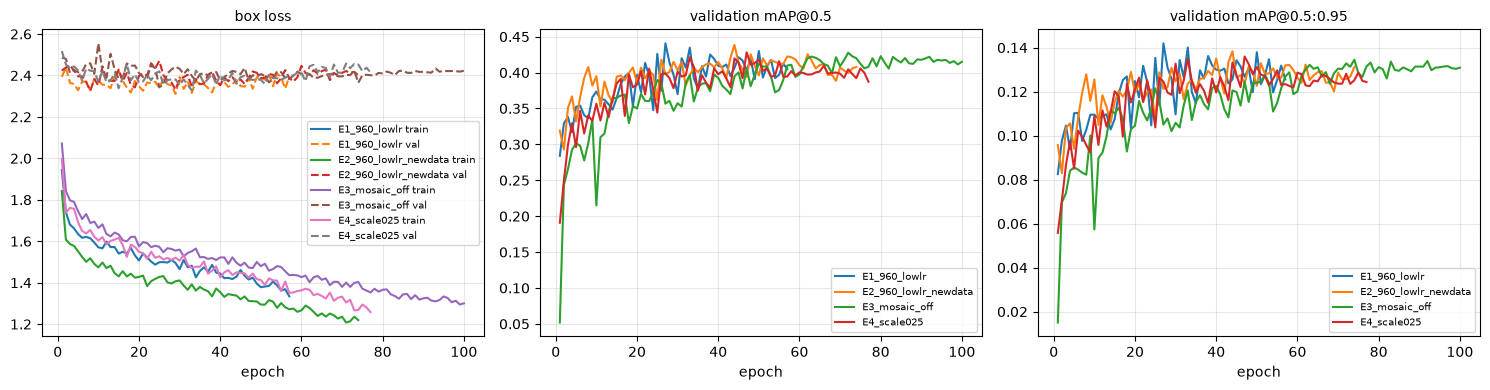

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for rid in RUN_IDS:
    f = LE.RUNS / rid / "results.csv"
    if not f.exists(): continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
    ax[0].plot(r["epoch"], r["train/box_loss"], label=rid + " train"); ax[0].plot(r["epoch"], r["val/box_loss"], "--", label=rid + " val"); ax[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=rid); ax[2].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=rid)
for a, t in zip(ax, ("box loss", "validation mAP@0.5", "validation mAP@0.5:0.95")): a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Every finished epoch of every experiment (scroll; a `*` marks a new best mAP@0.5)

In [5]:
pd.set_option("display.max_rows", None); pd.set_option("display.width", 220)
cols = {"epoch": "epoch", "train/box_loss": "box_loss", "train/cls_loss": "cls_loss", "train/dfl_loss": "dfl_loss", "metrics/precision(B)": "P", "metrics/recall(B)": "R", "metrics/mAP50(B)": "mAP50", "metrics/mAP50-95(B)": "mAP50-95"}
for rid in RUN_IDS:
    f = LE.RUNS / rid / "results.csv"
    if not f.exists(): print(rid, ": no results yet"); continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]; t = r[list(cols)].rename(columns=cols); t["epoch"] = t["epoch"].astype(int); t["best so far"] = np.where(t["mAP50"] == t["mAP50"].cummax(), "*", "")
    print("=" * 100); print("%s | %d finished epochs | best mAP@0.5 %.3f at epoch %d" % (rid, len(t), t["mAP50"].max(), int(t.loc[t["mAP50"].idxmax(), "epoch"]))); display(t.round(3).set_index("epoch"))

E1_960_lowlr | 57 finished epochs | best mAP@0.5 0.441 at epoch 27


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.944,2.417,1.583,0.360,0.353,0.284,0.083,*
2,1.740,1.748,1.427,0.400,0.397,0.329,0.098,*
3,1.680,1.655,1.381,0.384,0.428,0.338,0.105,*
4,1.662,1.621,1.355,0.387,0.414,0.317,0.094,
5,1.635,1.580,1.360,0.426,0.405,0.352,0.110,*
6,1.617,1.555,1.324,0.431,0.397,0.354,0.110,*
7,1.621,1.640,1.365,0.401,0.422,0.341,0.098,
8,1.615,1.577,1.329,0.425,0.373,0.336,0.103,
9,1.593,1.510,1.317,0.393,0.435,0.366,0.110,*


E2_960_lowlr_newdata | 74 finished epochs | best mAP@0.5 0.438 at epoch 44


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.842,2.282,1.491,0.403,0.394,0.319,0.096,*
2,1.608,1.636,1.343,0.354,0.394,0.293,0.083,
3,1.587,1.543,1.318,0.428,0.398,0.351,0.103,*
4,1.577,1.520,1.327,0.413,0.440,0.367,0.106,*
5,1.551,1.437,1.311,0.392,0.390,0.332,0.094,
6,1.524,1.396,1.291,0.405,0.444,0.366,0.108,
7,1.500,1.359,1.266,0.440,0.452,0.393,0.120,*
8,1.518,1.384,1.272,0.442,0.452,0.408,0.128,*
9,1.490,1.346,1.274,0.414,0.459,0.382,0.116,


E3_mosaic_off | 100 finished epochs | best mAP@0.5 0.428 at epoch 72


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,2.072,3.261,1.545,0.079,0.376,0.052,0.015,*
2,1.843,1.879,1.421,0.316,0.339,0.243,0.070,*
3,1.797,1.798,1.410,0.337,0.347,0.265,0.074,*
4,1.790,1.754,1.420,0.411,0.341,0.292,0.084,*
5,1.745,1.762,1.399,0.369,0.380,0.301,0.086,*
6,1.707,1.678,1.381,0.362,0.389,0.298,0.085,
7,1.731,1.646,1.406,0.377,0.323,0.278,0.083,
8,1.688,1.647,1.373,0.398,0.377,0.302,0.082,*
9,1.695,1.598,1.378,0.424,0.385,0.335,0.100,*


E4_scale025 | 77 finished epochs | best mAP@0.5 0.428 at epoch 47


,box_loss,cls_loss,dfl_loss,P,R,mAP50,mAP50-95,best so far
epoch,,,,,,,,
1,1.998,2.770,1.478,0.297,0.298,0.191,0.056,*
2,1.738,1.750,1.348,0.351,0.327,0.250,0.071,*
3,1.761,1.702,1.360,0.387,0.375,0.299,0.087,*
4,1.757,1.675,1.370,0.439,0.383,0.329,0.098,*
5,1.692,1.620,1.342,0.414,0.351,0.296,0.085,
6,1.650,1.540,1.318,0.428,0.396,0.347,0.102,*
7,1.638,1.559,1.315,0.413,0.383,0.315,0.099,
8,1.655,1.521,1.304,0.410,0.409,0.340,0.096,
9,1.621,1.558,1.302,0.400,0.435,0.333,0.092,


## 5. Comparison with the baseline and the decision rule
Every model (best epoch) is scored with the same scorer on the same validation photos, at the confidence with the best F1. The result is also appended to `EXPERIMENTS.csv` (the project's record of every run).

In [6]:
import hashlib
reg = pd.read_csv(LE.REG); b = reg[reg.id == "A0_base"].iloc[0]
rows = [dict(run="A0 baseline", mAP50=b.val_mAP50, mAP50_95=b.val_mAP50_95, precision=b.val_P, recall=b.val_R, F1=b.val_F1, dmAP50=0.0, passes_rule="")]; log = []
for rid in RUN_IDS:
    w = LE.RUNS / rid / "weights" / "best.pt"
    if not w.exists(): continue
    sp = json.loads((LE.RUNS / rid / "spec.json").read_text()); imgsz = sp["args"]["imgsz"]; sv = H.score_model(w, imgsz, LE.ACNE / "val"); c = H.best_f1_conf(sv); p, r, f = H.at_conf(sv, c); d = sv["AP50"] - b.val_mAP50
    ok = d >= 0.02 and p >= b.val_P - 0.02 and r >= b.val_R - 0.02
    rows.append(dict(run=rid, mAP50=sv["AP50"], mAP50_95=sv["AP50_95"], precision=p, recall=r, F1=f, dmAP50=d, passes_rule="YES" if ok else "no"))
    if QUICK_TEST: continue
    tl = [l for l in (LE.RUNS / rid / "train_list.txt").read_text().splitlines() if l]; res = pd.read_csv(LE.RUNS / rid / "results.csv"); res.columns = [c.strip() for c in res.columns]
    log.append(dict(id=rid, condition="acne", recipe=sp["recipe"], seed=sp["seed"], model="yolov8s.pt", imgsz=imgsz, overrides=json.dumps({k: v for k, v in sp["args"].items() if LE.BASE_ARGS.get(k) != v and k != "model"}), note=sp["note"],
                    train_photos=len(tl), dataset_fingerprint=hashlib.sha256("\n".join(sorted(tl)).encode()).hexdigest()[:16], epochs_run=len(res), best_epoch=int(res["metrics/mAP50(B)"].idxmax()) + 1, train_minutes=round(float(res["time"].iloc[-1]) / 60, 1),
                    val_set="val", val_mAP50=round(sv["AP50"], 4), val_mAP50_95=round(sv["AP50_95"], 4), val_conf=round(c, 3), val_P=round(p, 3), val_R=round(r, 3), val_F1=round(f, 3), status="ok"))
CMP = pd.DataFrame(rows); display(CMP.round(3))
if log and not any(reg.id.isin([l["id"] for l in log])): LE.log_rows(log); print("results appended to", LE.REG)
print("rule: adopt only if validation mAP@0.5 gains at least +0.02 and neither precision nor recall drops by more than 0.02 (single seed; seed noise about +/-0.006)")

,run,mAP50,mAP50_95,precision,recall,F1,dmAP50,passes_rule
0,A0 baseline,0.425,0.136,0.486,0.503,0.494,0.000,
1,E1_960_lowlr,0.452,0.144,0.508,0.482,0.495,0.027,no
2,E2_960_lowlr_newdata,0.441,0.139,0.516,0.495,0.505,0.016,no
3,E3_mosaic_off,0.414,0.133,0.440,0.500,0.468,-0.011,no
4,E4_scale025,0.436,0.139,0.544,0.441,0.487,0.011,no


results appended to /home/bautista/PrecisionSkinV1/lesion_experiments/EXPERIMENTS.csv
rule: adopt only if validation mAP@0.5 gains at least +0.02 and neither precision nor recall drops by more than 0.02 (single seed; seed noise about +/-0.006)


## 6. What to do with the result
- Write down which experiments passed the rule (`passes_rule` = YES). Only those go into Phase 2.
- If none passes, say so: Phase 2 then uses the baseline settings (or the best single change if you choose, stating that it did not pass the rule).
- Do not look at the test photos to decide anything. Next: `PrecisionSkin_Acne_Phase2_FinalTraining.ipynb`.